### Problem 9.2 : Applying QSVM with PennyLane

PennyLane is an open-source software framework for quantum machine learning, quantum chemistry, and quantum computing, with the ability to run on all hardware.

Link - https://pennylane.ai/datasets/

#### Why Use PennyLane?
- **Hybrid Quantum-Classical Learning:** PennyLane allows seamless integration between quantum circuits and classical machine learning libraries like TensorFlow or PyTorch, enabling hybrid models that leverage both classical and quantum computing strengths.
- **Flexibility in Device Choice: **With various backend options (simulators and real devices), users can choose based on performance needs or availability.
- **Automatic Differentiation:** PennyLane supports automatic differentiation, making it easier to optimize parameters within quantum circuits using gradient-based methods.


In [1]:
# !pip install pennylane
# !pip install pennylane --upgrade

In [2]:
import pennylane as qml
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

import matplotlib.pyplot as plt
from sklearn.svm import SVC

**qml.device:** 
- **Definition:** This function is used to load a specific quantum device on which quantum circuits will be executed. It creates an instance of the Device class, which interprets and executes quantum operations.
- **Usage:** You specify the type of device (e.g., default.qubit, lightning.qubit) and parameters such as the number of qubits (wires) and whether to use shots for statistical sampling.

In [3]:
# Define a PennyLane device
n_qubits = 2
dev = qml.device("default.qubit", wires=n_qubits)


**qml.qnode:**
- **Definition: **A QNode is a decorator that wraps a Python function containing quantum operations. It encapsulates the quantum circuit and associates it with a specific device.
- **Usage: **You define a quantum function that includes quantum gates and measurements, then use the @qml.qnode(dev) decorator to create a QNode.

Pauli Z gate Knowledge Link - https://www.sharetechnote.com/html/QC/QuantumComputing_Gate_X.html

In [4]:
@qml.qnode(dev)
def circuit(x):
    # A small illustration of a QNode - NOT the kernel itself (see the next section)
    qml.RX(x[0], wires=0)
    qml.RX(x[1], wires=1)
    qml.CNOT(wires=[0, 1])
    return qml.expval(qml.PauliZ(0))  # Pauli Z Operator


----
### What makes something a *kernel* ?

It is tempting to write something like

```python
kernel[i, j] = circuit(X1[i]) * circuit(X2[j])      #  <-- WRONG
```

but that is **not a kernel**. A kernel must be a *similarity between a pair of points* -
k(x, x') has to depend on x and x' **together**. The expression above just multiplies two
numbers that were each computed from one point in isolation, so:

- the resulting matrix has rank 1 (every row is a multiple of every other row),
- k(x, x) is not maximal, and the matrix is not even guaranteed to be positive semi-definite,
- the SVM sees no useful geometry at all and effectively falls back to guessing.

The correct quantum kernel is the **fidelity** between the two encoded states :

**k(x, x′) = |⟨φ(x′)∣φ(x)⟩|²**

and there is a neat way to compute it on hardware. Encode x, then apply the **adjoint** (inverse)
of the encoding for x′, and measure the probability of getting the all-zeros bitstring :

**P(00…0) = |⟨φ(x′)∣φ(x)⟩|²**

If the two states are identical the inverse undoes the encoding perfectly and we always measure
zeros (k = 1). The more different they are, the smaller that probability gets. This "embed then
un-embed" trick is the standard way of building a quantum kernel, and it is exactly what
`FidelityQuantumKernel` did for us in Problems 9 and 9.1.

In [5]:
def feature_map(x):
    """Encode one classical 2D point into the state of 2 qubits."""
    qml.AngleEmbedding(x, wires=range(n_qubits), rotation='Y')  # one rotation per feature
    qml.CNOT(wires=[0, 1])                                      # entangle the two qubits
    qml.RZ(x[0] * x[1], wires=1)                                # a term that mixes the features
    qml.CNOT(wires=[0, 1])


@qml.qnode(dev)
def kernel_circuit(x1, x2):
    """Embed x1, un-embed x2, and read out the probability of every bitstring."""
    feature_map(x1)
    qml.adjoint(feature_map)(x2)
    return qml.probs(wires=range(n_qubits))


def kernel(x1, x2):
    """k(x1, x2) = |<phi(x2)|phi(x1)>|^2  -  the probability of measuring |00>."""
    return kernel_circuit(x1, x2)[0]


In [6]:
# Sanity checks - any real kernel must pass these
a = np.array([0.3, -0.7])
b = np.array([1.1, 0.4])

print("k(a, a) =", kernel(a, a), " <- must be 1.0, a point is identical to itself")
print("k(a, b) =", kernel(a, b))
print("k(b, a) =", kernel(b, a), " <- must equal k(a, b), a kernel is symmetric")


k(a, a) = 0.9999999999999996  <- must be 1.0, a point is identical to itself
k(a, b) = 0.612027949688283
k(b, a) = 0.612027949688283  <- must equal k(a, b), a kernel is symmetric


In [7]:
def compute_kernel(X1, X2):
    """Compute the kernel matrix using PennyLane."""
    n_samples_1 = X1.shape[0]
    n_samples_2 = X2.shape[0]
    kernel_matrix = np.zeros((n_samples_1, n_samples_2))

    for i in range(n_samples_1):
        for j in range(n_samples_2):
            kernel_matrix[i, j] = kernel(X1[i], X2[j])

    return kernel_matrix


In [8]:
def generate_circle_data(n_samples=100, noise=0.1, seed=42):
    # Fix the seed so the notebook gives the same numbers every time you run it
    np.random.seed(seed)

    # Generate circle dataset
    phi = 2 * np.pi * np.random.random(n_samples)
    r = np.random.random(n_samples)

    X = np.zeros((n_samples, 2))
    X[:, 0] = r * np.cos(phi)
    X[:, 1] = r * np.sin(phi)

    y = 2 * (r > 0.5) - 1

    if noise > 0:
        X += noise * np.random.randn(*X.shape)

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    return X_scaled, y


In [9]:
# Omit this section from your logical understanding, this is just for visualisation

import matplotlib.pyplot as plt

def visualize_data(X, y, title="Circle Dataset"):
    """Visualize the dataset."""
    plt.figure(figsize=(10, 8))
    plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], c='b', marker='o', label='Class 1', alpha=0.6)
    plt.scatter(X[y == -1][:, 0], X[y == -1][:, 1], c='r', marker='x', label='Class -1', alpha=0.6)
    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.legend()
    plt.grid(True)
    plt.axis('equal')  # Ensure equal scaling
    plt.show()

def visualize_predictions(X_test, y_test, y_pred):
    """Visualize predictions on test data."""
    plt.figure(figsize=(10, 8))
    
    # Plot true labels
    plt.scatter(X_test[y_test == 1][:, 0], X_test[y_test == 1][:, 1], c='b', marker='o', label='True Class 1', alpha=0.6)
    plt.scatter(X_test[y_test == -1][:, 0], X_test[y_test == -1][:, 1], c='r', marker='x', label='True Class -1', alpha=0.6)

    # Plot predicted labels
    plt.scatter(X_test[y_pred == 1][:, 0], X_test[y_pred == 1][:, 1], c='cyan', marker='o', edgecolor='black', label='Predicted Class 1', alpha=0.4)
    plt.scatter(X_test[y_pred == -1][:, 0], X_test[y_pred == -1][:, 1], c='magenta', marker='x', edgecolor='black', label='Predicted Class -1', alpha=0.4)

    plt.title("Test Data with Predictions")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.legend()
    plt.grid(True)
    plt.axis('equal') 
    plt.show()


In [10]:
def create_and_train_qsvm(X_train, X_test, y_train):
    # Compute kernel matrices using PennyLane
    print("Computing kernel matrices...")
    
    # Kernel matrix for training data (training against itself)
    kernel_matrix_train = compute_kernel(X_train, X_train)
    
    # Kernel matrix for test data against training data
    kernel_matrix_test = compute_kernel(X_test, X_train)

    # Train SVM
    svm = SVC(kernel='precomputed')
    
    # Fit SVM with the training kernel matrix
    svm.fit(kernel_matrix_train, y_train)

    # Make predictions using the test kernel matrix
    y_pred = svm.predict(kernel_matrix_test)
    
    return y_pred

Generating circle dataset...

This function creates a scatter plot of the original circle dataset.
Points belonging to different classes are colored differently (blue for Class +1 and red for Class -1).



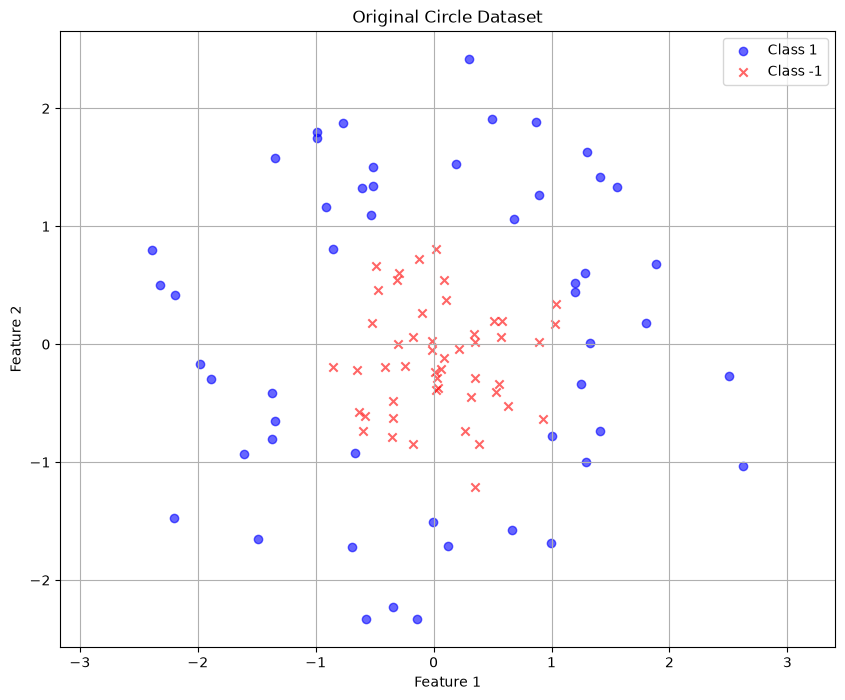

In [11]:
print("Generating circle dataset...")
X_scaled, y = generate_circle_data(n_samples=100, noise=0.1)

print("""
This function creates a scatter plot of the original circle dataset.
Points belonging to different classes are colored differently (blue for Class +1 and red for Class -1).
""")
visualize_data(X_scaled, y, title="Original Circle Dataset")

In [12]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

print("\nTraining QSVM...")
y_pred = create_and_train_qsvm(X_train, X_test, y_train)

print("\nResults:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Training QSVM...
Computing kernel matrices...



Results:
Accuracy: 0.9666666666666667

Classification Report:
              precision    recall  f1-score   support

          -1       1.00      0.94      0.97        16
           1       0.93      1.00      0.97        14

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30




This function visualizes both the true labels and predicted labels of the test dataset after training the QSVM. 
The true classes are shown in blue and red as before while 
      predicted classes are shown in cyan and magenta with a slight transparency to distinguish them from true labels.



/var/folders/4m/t57l_3js7tb4vz_rmr3_ntch0000gn/T/ipykernel_11054/2800770217.py:28: UserWarning: You passed an edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_test[y_pred == -1][:, 0], X_test[y_pred == -1][:, 1], c='magenta', marker='x', edgecolor='black', label='Predicted Class -1', alpha=0.4)


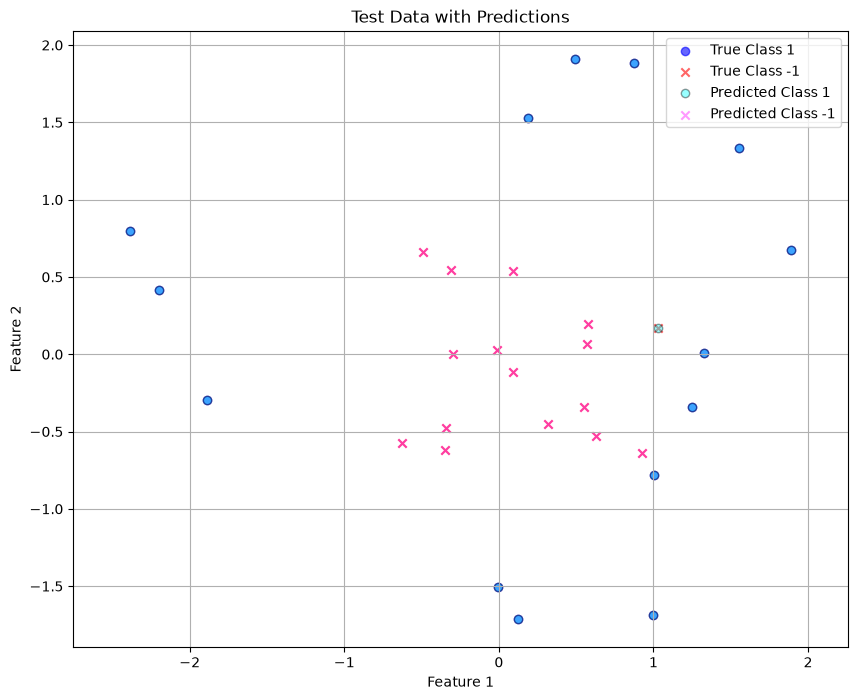

In [13]:
print("""
This function visualizes both the true labels and predicted labels of the test dataset after training the QSVM. 
The true classes are shown in blue and red as before while 
      predicted classes are shown in cyan and magenta with a slight transparency to distinguish them from true labels.
""")
visualize_predictions(X_test, y_test, y_pred)

----
#### How good is that, really ?

A quantum kernel is only interesting if it is *competitive*. The honest thing to do is always to
run the same data through a good classical kernel and compare. Let us do that.

In [14]:
from sklearn.svm import SVC

classical = SVC(kernel='rbf')
classical.fit(X_train, y_train)
y_pred_classical = classical.predict(X_test)

print("Quantum kernel accuracy  :", accuracy_score(y_test, y_pred))
print("Classical RBF accuracy   :", accuracy_score(y_test, y_pred_classical))


Quantum kernel accuracy  : 0.9666666666666667
Classical RBF accuracy   : 0.9666666666666667


On this dataset the two are neck and neck - and that is the honest, expected result. For small,
low-dimensional, classically easy problems a quantum kernel has nothing to prove; the RBF kernel
is excellent and runs in microseconds. Quantum kernels are researched because there exist
feature maps that are believed to be *hard to simulate classically*, not because they beat
scikit-learn on toy circles.

Keep this comparison habit for every quantum model you build. "It got 96%" means little on its
own; "it got 96% where the classical baseline gets 96%" is a real result.